# Practical Work: House sales
RealAgents is a real estate company that focuses on selling houses.

RealAgents sells a variety of types of house in one metropolitan area.

Some houses sell slowly and sometimes require lowering the price in order to find a buyer.

In order to stay competitive, RealAgents would like to optimize the listing prices of the houses it is trying to sell.

They want to do this by predicting the sale price of a house given its characteristics.

If they can predict the sale price in advance, they can decrease the time to sale.

# First look to the dataset:
Check the dimensions (1500 rows, 8 columns) to understand dataset size, and preview the first 5 rows (head()) to spot immediate anomalies.

Even in just 5 rows, a sharp data scientist already spots two hidden problems: house_type has inconsistent abbreviations ("Det." vs. "Detached"), and area contains text units ("107.8 sq.m."), which means Python treats it as text instead of a number.

In [2]:
import pandas as pd
df = pd.read_csv("house_sales.csv")
print(df.shape)
df.head()

(1500, 8)


,house_id,city,sale_price,sale_date,months_listed,bedrooms,house_type,area
0,1217792,Silvertown,55943,2021-09-12,5.4,2,Semi-detached,107.8 sq.m.
1,1900913,Silvertown,384677,2021-01-17,6.3,5,Detached,498.8 sq.m.
2,1174927,Riverford,281707,2021-11-10,6.9,6,Detached,542.5 sq.m.
3,1773666,Silvertown,373251,2020-04-13,6.1,6,Det.,528.4 sq.m.
4,1258487,Silvertown,328885,2020-09-24,8.7,5,Detached,477.1 sq.m.


# Check data types (Dtype) and non-null counts against your problem schema.

months_listed has 1469 non-null entries out of 1500 (meaning 31 are missing). Also, sale_date is stored as an object (string) rather than a date.

In [3]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   house_id       1500 non-null   int64  
 1   city           1500 non-null   object 
 2   sale_price     1500 non-null   int64  
 3   sale_date      1500 non-null   object 
 4   months_listed  1469 non-null   float64
 5   bedrooms       1500 non-null   int64  
 6   house_type     1500 non-null   object 
 7   area           1500 non-null   object 
dtypes: float64(1), int64(3), object(4)
memory usage: 93.9+ KB
None


# Quantify explicit missing values (NaN) across all columns.
It confirms months_listed has 31 missing values and suggests city has 0—however, never trust isnull() alone when domain rules say missing data exists!

In [4]:
print(df.isnull().sum())

house_id          0
city              0
sale_price        0
sale_date         0
months_listed    31
bedrooms          0
house_type        0
area              0
dtype: int64


# Before blindly filling missing numbers, check their distribution.
If data is heavily skewed with extreme outliers, the median is safer than the mean. Because this histogram is fairly balanced (roughly bell-shaped around 5–8 months), imputing with the mean is statistically sound

<Axes: >

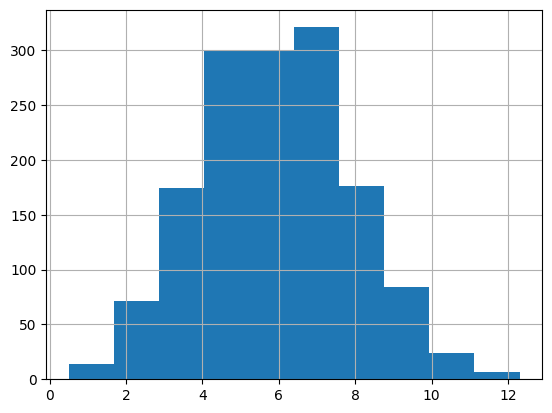

In [5]:
df['months_listed'].hist()

# fillna vs. SimpleImputer

Pandas fillna(): Quick for exploratory analysis, though using inplace=True triggers a FutureWarning in modern pandas—a great teaching moment on writing clean, future-proof code (df[col] = df[col].fillna(...)).

In [6]:
df['months_listed'].fillna(df['months_listed'].mean(), inplace=True)

/tmp/ipykernel_1085/2953535283.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['months_listed'].fillna(df['months_listed'].mean(), inplace=True)


In [7]:
print(df.isnull().sum())

house_id         0
city             0
sale_price       0
sale_date        0
months_listed    0
bedrooms         0
house_type       0
area             0
dtype: int64


Scikit-Learn SimpleImputer(strategy='mean'): The production-grade ML approach. Using SimpleImputer prevents data leakage later when building machine learning pipelines on train/test splits.

In [8]:
# or a second method
from sklearn.impute import SimpleImputer

# Create the imputer using the mean strategy
imputer = SimpleImputer(strategy='mean')

# Impute missing values in months_listed
df[['months_listed']] = imputer.fit_transform(df[['months_listed']])

# Check missing values
print(df.isnull().sum())

house_id         0
city             0
sale_price       0
sale_date        0
months_listed    0
bedrooms         0
house_type       0
area             0
dtype: int64


# Catching disguised missing values.
The business prompt explicitly warned that city has missing values, yet isnull().sum() returned 0. Inspecting .unique() reveals why: missing cities were recorded as the string "--" (73 times)! Checking .unique() on categorical columns is non-negotiable.

In [9]:
print(df["city"].unique())
print(df["house_type"].unique())
missing_city = (df["city"] == "--").sum()
print(missing_city)

['Silvertown' 'Riverford' 'Teasdale' 'Poppleton' '--']
['Semi-detached' 'Detached' 'Det.' 'Terraced' 'Semi' 'Terr.']
73


In [10]:
df["city"].value_counts(dropna=False)

,count
city,
Silvertown,517
Teasdale,366
Poppleton,362
Riverford,182
--,73


In [11]:
clean_data = df.copy()

In [12]:
# Use this cell to write your code for Task 2
valid_cities = ['Silvertown', 'Riverford', 'Teasdale', 'Poppleton']

clean_data['city'] = df['city'].where(
    df['city'].isin(valid_cities),
    'Unknown'
)

In [13]:
clean_data["city"] = clean_data["city"].str.strip()
print(clean_data["city"].unique())

['Silvertown' 'Riverford' 'Teasdale' 'Poppleton' 'Unknown']


In [14]:
# Check missing values
missings = df["sale_price"].isna().sum()
print(missings)

# Check if any sale prices are negative
negatives = (df["sale_price"] < 0).sum()
print(negatives)

# Check if all remaining values are valid
(df["sale_price"] >= 0).all()

clean_data['sale_price'] = df['sale_price']
clean_data = clean_data.dropna(subset=["sale_price"])

0
0


In [15]:
clean_data["sale_date"] = pd.to_datetime(
    df["sale_date"].fillna("2023-01-01")
)

In [16]:
# Calculate the mean (rounded to 1 decimal place)
mean_months = round(df["months_listed"].mean(), 1)

# Replace missing values
clean_data["months_listed"] = df["months_listed"].fillna(mean_months)

In [17]:
mean_bedrooms = round(df["bedrooms"].mean())
clean_data["bedrooms"] = df["bedrooms"].fillna(mean_bedrooms)

In [18]:
clean_data["house_type"] = df["house_type"].fillna(
    df["house_type"].mode()[0]
)

In [19]:
print(clean_data["house_type"].unique())

['Semi-detached' 'Detached' 'Det.' 'Terraced' 'Semi' 'Terr.']


In [20]:
clean_data["house_type"] = (
    clean_data["house_type"]
    .str.strip()
    .replace({
        "Det.": "Detached",
        "Semi": "Semi-detached",
        "Semi-Detached": "Semi-detached",
        "Terr.": "Terraced"
    })
)
print(clean_data["house_type"].unique())

['Semi-detached' 'Detached' 'Terraced']


In [21]:
# Remove ' sq.m.' and convert to numeric
df["area"] = pd.to_numeric(
    df["area"].str.replace(" sq.m.", "", regex=False),
    errors="coerce"
)

# Fill missing values with the mean rounded to 1 decimal
mean_area = round(df["area"].mean(), 1)
clean_data["area"] = df["area"].fillna(mean_area)


In [22]:
print(clean_data.head())

   house_id        city  sale_price  sale_date  months_listed  bedrooms  \
0   1217792  Silvertown       55943 2021-09-12            5.4         2   
1   1900913  Silvertown      384677 2021-01-17            6.3         5   
2   1174927   Riverford      281707 2021-11-10            6.9         6   
3   1773666  Silvertown      373251 2020-04-13            6.1         6   
4   1258487  Silvertown      328885 2020-09-24            8.7         5   

      house_type   area  
0  Semi-detached  107.8  
1       Detached  498.8  
2       Detached  542.5  
3       Detached  528.4  
4       Detached  477.1  


In [23]:
print(clean_data.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   house_id       1500 non-null   int64         
 1   city           1500 non-null   object        
 2   sale_price     1500 non-null   int64         
 3   sale_date      1500 non-null   datetime64[ns]
 4   months_listed  1500 non-null   float64       
 5   bedrooms       1500 non-null   int64         
 6   house_type     1500 non-null   object        
 7   area           1500 non-null   float64       
dtypes: datetime64[ns](1), float64(2), int64(3), object(2)
memory usage: 93.9+ KB
None


# TASK 05: Machine Learning Workflow

Separate predictors (X) from the target (y = sale_price)

In [25]:
X = clean_data.drop("sale_price", axis=1)  # Input features
y = clean_data["sale_price"]

In [26]:
# 2. Extract useful numerical features from sale_date (since LinearRegression can't take raw datetime objects)
X["sale_year"] = X["sale_date"].dt.year
X["sale_month"] = X["sale_date"].dt.month
X = X.drop("sale_date", axis=1)

convert categorical text into binary columns (pd.get_dummies(..., drop_first=True)) so regression math can process them

In [27]:
X_encoded = pd.get_dummies(X, drop_first=True)

split into training and testing sets (train_test_split) to evaluate performance on unseen data.

In [28]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y,
    test_size=0.2,
    random_state=42
)

In [29]:
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)

Training features: (1200, 12)
Testing features: (300, 12)
Training labels: (1200,)
Testing labels: (300,)


In [30]:
from sklearn.linear_model import LinearRegression
model = LinearRegression()
model.fit(X_train, y_train)

LinearRegression()

In [31]:
y_pred = model.predict(X_test)

comparison = pd.DataFrame({
    'Actual Price': y_test.values,
    'Predicted Price': y_pred,
    'Difference': y_test.values - y_pred
})

print(comparison.head())

   Actual Price  Predicted Price    Difference
0         37360     26686.858517  10673.141483
1        408034    363747.491431  44286.508569
2        191761    212861.027203 -21100.027203
3        250823    256709.955988  -5886.955988
4         52229     57010.275166  -4781.275166


In [32]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("MSE:", mse)
print("MAE:", mae)
print("R2 Score:", r2)

MSE: 494945406.1302689
MAE: 16909.182919333634
R2 Score: 0.962422750520888


In [33]:
from sklearn.ensemble import RandomForestRegressor

# Fit the comparison model
model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)
model.fit(X_train, y_train)

# Predict on validation set
y_pred = model.predict(X_test)

comparison = pd.DataFrame({
    'Actual Price': y_test.values,
    'Predicted Price': y_pred,
    'Difference': y_test.values - y_pred
})

print(comparison.head())

   Actual Price  Predicted Price  Difference
0         37360         36187.03     1172.97
1        408034        368454.92    39579.08
2        191761        213358.08   -21597.08
3        250823        251515.12     -692.12
4         52229         56103.64    -3874.64


In [34]:
mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("MSE:", mse)
print("MAE:", mae)
print("R2 Score:", r2)

MSE: 345858628.90736866
MAE: 12080.666200000001
R2 Score: 0.9737417181329789
